# Chapter 4, Regions Over Time: How Brazil's Electoral Map Moved, 1998–2026

## The story so far

Chapter 3 showed the 2026 comeback was arithmetically covered by eliminated votes plus new valid votes, and broad across municipalities. But was 2026 *unusual* compared with Brazil's own history? This chapter answers that, region by region and state by state, using decisive-round results from 1998 to 2026.

## Two definitions, stated once

- **Decisive round.** The round that decided the election: round 2 if there was a runoff, round 1 if the winner passed 50% immediately (as in 1998). Every share below is a share of *valid* votes in that decisive round.
- **The PT candidate.** Each year there is one Workers' Party (PT) presidential candidate: Lula in 1998, 2002, 2006, 2022 and 2026; Dilma Rousseff in 2010 and 2014; Fernando Haddad in 2018. Tracking "the PT candidate's share" therefore tracks one political lineage across eight elections, it is not a claim that the candidates or their platforms were identical. The winner each year, PT or not, is also recorded.

**Coverage note.** The TSE municipality/zone series used here starts in 1998, so this chapter starts in 1998. The national runoff-history table in Chapter 2 covers 1989–2026; 1989 and 1994 are not in the regional series, and the notebooks do not pretend otherwise.

> **Dispute label.** The 2026 results in this chapter are the TSE count, contested by Flávio Bolsonaro as described in Chapters 2 and 5 and accepted by the TSE, foreign governments, and the PL. The historical comparison does not, by itself, prove or disprove any fraud claim, that is Chapter 5's job.

In [1]:
# Install what this notebook needs (safe to re-run; needed on Google Colab)
!pip install -q pandas matplotlib geopandas

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [2]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed


In [3]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
hist = pd.read_csv(PROC / "hist_state.csv")
print(f"History rows: {len(hist):,} (states x elections, incl. overseas ZZ in some years)")
print(f"Years: {sorted(hist['year'].unique())}")
print(f"Elections per year (decisive round):")
print(hist.groupby("year")["decisive_round"].first().to_string())
UFS27 = ["AC","AL","AM","AP","BA","CE","DF","ES","GO","MA","MG","MS","MT","PA","PB","PE","PI","PR","RJ","RN","RO","RR","RS","SC","SE","SP","TO"]
dom = hist[hist["SG_UF"].isin(UFS27)].copy()  # excludes ZZ (abroad) and VT (2010 in-transit votes, not a state)
# Region aggregates: shares are vote-weighted (sums of votes), never averages of percentages.
reg = dom.groupby(["region", "year"], as_index=False).agg(
    pt_votes=("pt_votes", "sum"), valid=("valid", "sum"),
    aptos=("QT_APTOS", "sum"), comparecimento=("QT_COMPARECIMENTO", "sum"),
    abstencoes=("QT_ABSTENCOES", "sum"))
reg["pt_share"] = reg["pt_votes"] / reg["valid"] * 100
reg["turnout"] = reg["comparecimento"] / reg["aptos"] * 100
reg["abstention"] = reg["abstencoes"] / reg["aptos"] * 100
print(); print(reg.pivot(index="year", columns="region", values="pt_share").round(1).to_string())
print()
print("PT candidate's decisive-round share by region (%), the Northeast is the PT's strongest region")
print("in every election in this series; the South is its weakest in most years. 2026 does not")
print("break that geography, it moves within it. See the chart and the table below for how much.")

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed
History rows: 225 (states x elections, incl. overseas ZZ in some years)
Years: [np.int64(1998), np.int64(2002), np.int64(2006), np.int64(2010), np.int64(2014), np.int64(2018), np.int64(2022), np.int64(2026)]
Elections per year (decisive round):
year
1998    1
2002    2
2006    2
2010    2
2014    2
2018    2
2022    2
2026    2

region  Center-West  North  Northeast  South  Southeast
year                                                   
1998           22.1   26.5       31.6   38.8       31.2
2002           57.3   58.2       61.5   58.8       63.0
2006           52.4   65.6       77.1   46.5       56.9
2010           49.1   57.4       70.6   46.1       51.9
2014           42.6   56.5       71.7   41.1       43.8
2018           33.5   48.1       69.7   31.7       34.6
2022           39.8   49.0       69.3   38.2       45.7
2026           40.0   50.0       69.4   37.4       47.2

PT candidate's decisive-round share 

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed


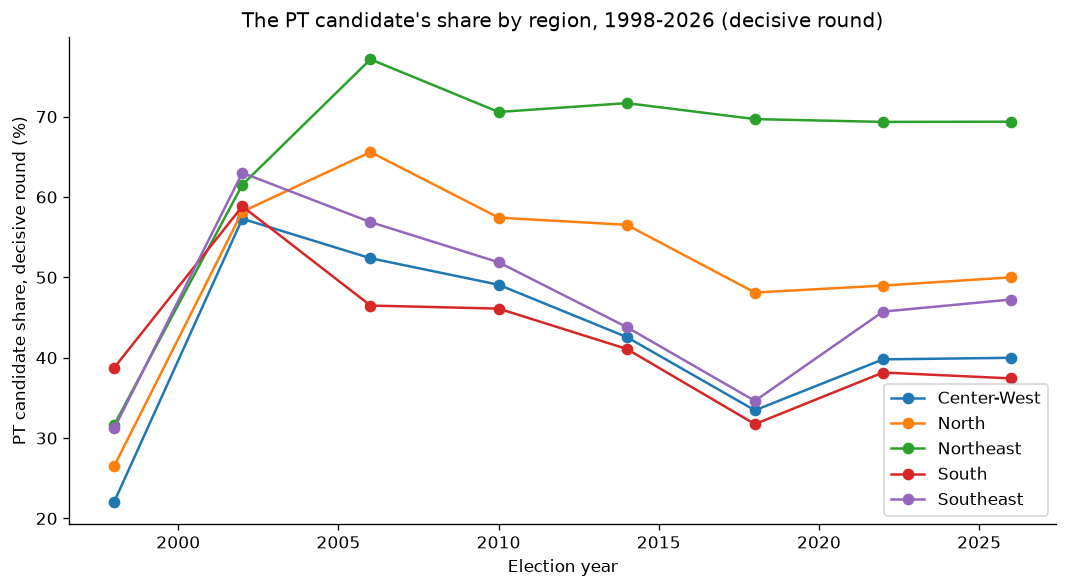

In [4]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
hist = pd.read_csv(PROC / "hist_state.csv")
UFS27 = ["AC","AL","AM","AP","BA","CE","DF","ES","GO","MA","MG","MS","MT","PA","PB","PE","PI","PR","RJ","RN","RO","RR","RS","SC","SE","SP","TO"]
dom = hist[hist["SG_UF"].isin(UFS27)].copy()  # excludes ZZ (abroad) and VT (2010 in-transit votes, not a state)
reg = dom.groupby(["region", "year"], as_index=False).agg(pt_votes=("pt_votes", "sum"), valid=("valid", "sum"))
reg["pt_share"] = reg["pt_votes"] / reg["valid"] * 100
fig, ax = plt.subplots(figsize=(9, 5))
for region, d in reg.groupby("region"):
    ax.plot(d["year"], d["pt_share"], marker="o", label=region)
ax.set_ylabel("PT candidate share, decisive round (%)")
ax.set_xlabel("Election year")
ax.set_title("The PT candidate's share by region, 1998-2026 (decisive round)")
ax.legend(); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(CHARTS / "04_pt_share_region.png"); plt.show()

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed


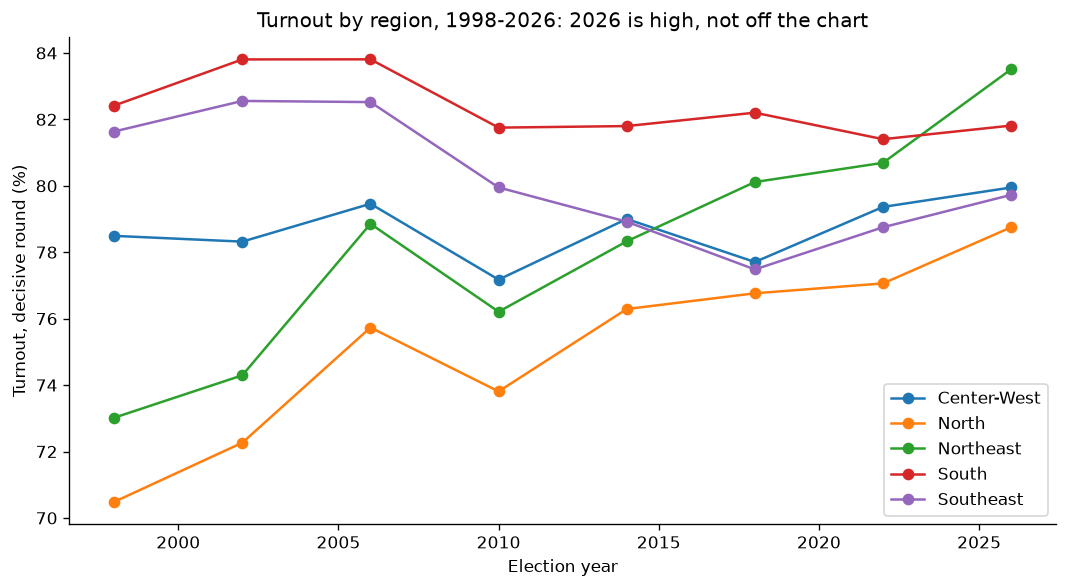

 year     aptos  comparecimento   turnout
 1998 106053106        83275929 78.522857
 2002 115184176        91628216 79.549309
 2006 125827119       101957338 81.029701
 2010 135527583       106465483 78.556321
 2014 142468510       112542006 78.994303
 2018 146805947       115732285 78.833513
 2022 155758433       123942648 79.573636
 2026 157828819       127854631 81.008419


In [5]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
hist = pd.read_csv(PROC / "hist_state.csv")
UFS27 = ["AC","AL","AM","AP","BA","CE","DF","ES","GO","MA","MG","MS","MT","PA","PB","PE","PI","PR","RJ","RN","RO","RR","RS","SC","SE","SP","TO"]
dom = hist[hist["SG_UF"].isin(UFS27)].copy()  # excludes ZZ (abroad) and VT (2010 in-transit votes, not a state)
reg = dom.groupby(["region", "year"], as_index=False).agg(
    aptos=("QT_APTOS", "sum"), comparecimento=("QT_COMPARECIMENTO", "sum"))
reg["turnout"] = reg["comparecimento"] / reg["aptos"] * 100
fig, ax = plt.subplots(figsize=(9, 5))
for region, d in reg.groupby("region"):
    ax.plot(d["year"], d["turnout"], marker="o", label=region)
ax.set_ylabel("Turnout, decisive round (%)")
ax.set_xlabel("Election year")
ax.set_title("Turnout by region, 1998-2026: 2026 is high, not off the chart")
ax.legend(); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(CHARTS / "04_turnout_region.png"); plt.show()
nat_hist = dom.groupby("year", as_index=False).agg(aptos=("QT_APTOS", "sum"), comparecimento=("QT_COMPARECIMENTO", "sum"))
nat_hist["turnout"] = nat_hist["comparecimento"] / nat_hist["aptos"] * 100
print(nat_hist.to_string(index=False))

## Which regions moved most in 2026, versus their own history?

A region that always votes one way and suddenly moves a little may matter less than a region that moves a lot relative to *its own* past. The table below compares each region's 2026 PT share with its average PT share across 1998–2022, and with its 2022 share (the most recent election). A positive difference means the PT candidate did better in 2026 than in that baseline.

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed
     region  pt_2026  pt_2022  mean_1998_2022  change_vs_mean  change_vs_2022
  Northeast    69.37    69.34           64.51            4.86            0.03
  Southeast    47.24    45.74           46.73            0.51            1.51
      North    50.01    48.97           51.62           -1.61            1.03
Center-West    39.99    39.79           42.37           -2.39            0.20
      South    37.42    38.16           43.02           -5.60           -0.73

Reading: a region can be the PT's strongest region AND move little in 2026, or a weak
region can move a lot. The 'change vs mean' column, not the level, is the 2026 surprise.


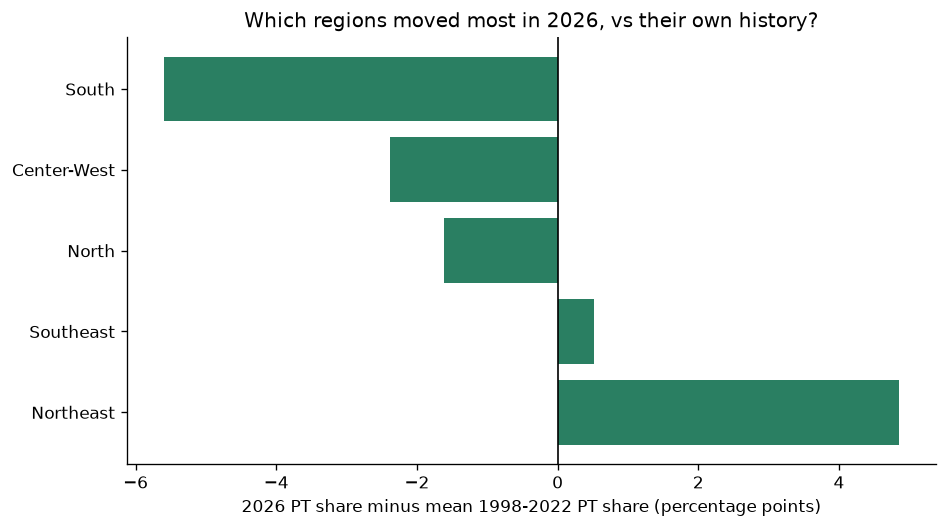

In [6]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
hist = pd.read_csv(PROC / "hist_state.csv")
UFS27 = ["AC","AL","AM","AP","BA","CE","DF","ES","GO","MA","MG","MS","MT","PA","PB","PE","PI","PR","RJ","RN","RO","RR","RS","SC","SE","SP","TO"]
dom = hist[hist["SG_UF"].isin(UFS27)].copy()  # excludes ZZ (abroad) and VT (2010 in-transit votes, not a state)
reg = dom.groupby(["region", "year"], as_index=False).agg(pt_votes=("pt_votes", "sum"), valid=("valid", "sum"))
reg["pt_share"] = reg["pt_votes"] / reg["valid"] * 100
rows = []
for region, d in reg.groupby("region"):
    mean_hist = d[d["year"] <= 2022]["pt_share"].mean()
    v2022 = d[d["year"] == 2022]["pt_share"].iloc[0]
    v2026 = d[d["year"] == 2026]["pt_share"].iloc[0]
    rows.append({"region": region, "pt_2026": v2026, "pt_2022": v2022,
                 "mean_1998_2022": mean_hist, "change_vs_mean": v2026 - mean_hist,
                 "change_vs_2022": v2026 - v2022})
comp = pd.DataFrame(rows).sort_values("change_vs_mean", ascending=False)
print(comp.round(2).to_string(index=False))
print()
print("Reading: a region can be the PT's strongest region AND move little in 2026, or a weak")
print("region can move a lot. The 'change vs mean' column, not the level, is the 2026 surprise.")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(comp["region"], comp["change_vs_mean"], color="#2a7f62")
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("2026 PT share minus mean 1998-2022 PT share (percentage points)")
ax.set_title("Which regions moved most in 2026, vs their own history?")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(CHARTS / "04_2026_vs_history.png"); plt.show()

## States: who flipped between 2022 and 2026?

A state "flips" here if the PT candidate won it (share ≥ 50% in the decisive round) in one election and lost it in the other. Flips are counted, not exaggerated: a state moving from 49.9% to 50.1% flips on paper but barely moved in votes, so the table also shows the size of each move.

In [7]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
hist = pd.read_csv(PROC / "hist_state.csv")
UFS27 = ["AC","AL","AM","AP","BA","CE","DF","ES","GO","MA","MG","MS","MT","PA","PB","PE","PI","PR","RJ","RN","RO","RR","RS","SC","SE","SP","TO"]
dom = hist[hist["SG_UF"].isin(UFS27)].copy()  # excludes ZZ (abroad) and VT (2010 in-transit votes, not a state)
piv = dom.pivot_table(index="SG_UF", columns="year", values="pt_share_valid", aggfunc="first")
piv["pt_won_2022"] = piv[2022] >= 0.5
piv["pt_won_2026"] = piv[2026] >= 0.5
piv["flipped"] = piv["pt_won_2022"] != piv["pt_won_2026"]
piv["change_pp"] = (piv[2026] - piv[2022]) * 100
print(f"States where the PT candidate's win/loss status changed 2022 -> 2026: {piv['flipped'].sum()}")
print(piv[piv["flipped"]][[2022, 2026, "change_pp"]].round(3).to_string())
print()
print("Largest PT-share moves (either direction), 2022 -> 2026:")
print(piv.reindex(piv["change_pp"].abs().sort_values(ascending=False).index)[[2022, 2026, "change_pp"]].head(10).round(3).to_string())

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed
States where the PT candidate's win/loss status changed 2022 -> 2026: 2
year    2022   2026  change_pp
SG_UF                         
AP     0.486  0.529      4.242
TO     0.514  0.486     -2.725

Largest PT-share moves (either direction), 2022 -> 2026:
year    2022   2026  change_pp
SG_UF                         
DF     0.412  0.457      4.536
AP     0.486  0.529      4.242
AC     0.297  0.334      3.735
RR     0.239  0.275      3.624
RJ     0.435  0.469      3.425
AM     0.511  0.540      2.921
TO     0.514  0.486     -2.725
SE     0.672  0.695      2.327
PE     0.669  0.692      2.269
AL     0.587  0.608      2.087


Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed


Mapped municipalities for state map: 5,564 (27 states)


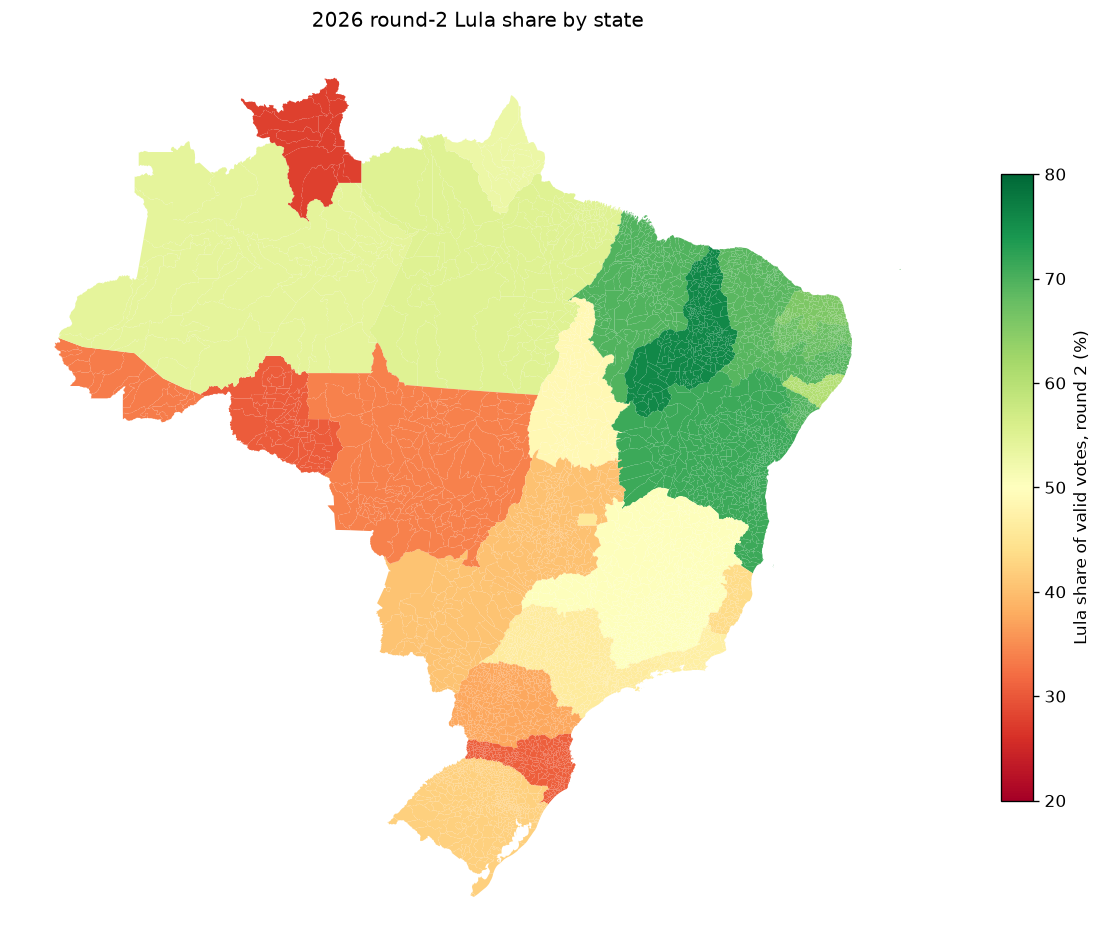

In [8]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
# State map for 2026: colour every municipality by its STATE's Lula share.
# (Dissolving municipalities into state polygons was tried and fails on invalid
# geometry in the mirror file, so the map is drawn at municipality resolution with
# no borders, visually it is a state choropleth, and it is exact.)
import geopandas as gpd
UF_IBGE = {"AC":"12","AL":"27","AM":"13","AP":"16","BA":"29","CE":"23","DF":"53","ES":"32",
           "GO":"52","MA":"21","MG":"31","MS":"50","MT":"51","PA":"15","PB":"25","PE":"26",
           "PI":"22","PR":"41","RJ":"33","RN":"24","RO":"11","RR":"14","RS":"43","SC":"42",
           "SE":"28","SP":"35","TO":"17"}
st = pd.read_csv(PROC / "state_2026.csv")
s2 = st[(st["NR_TURNO"] == 2) & (st["SG_UF"] != "ZZ")].copy()
s2["lula_share"] = s2["lula_share_valid"] * 100
s2["uf_code"] = s2["SG_UF"].map(UF_IBGE)
geo = gpd.read_file(ROOT / "data" / "raw" / "br_municipalities_geojson.json")
geo["uf_code"] = geo["id"].astype(str).str[:2]
merged = geo.merge(s2, on="uf_code", how="inner")
print(f"Mapped municipalities for state map: {len(merged):,} (27 states)")
fig, ax = plt.subplots(figsize=(10, 9))
merged.plot(column="lula_share", cmap="RdYlGn", vmin=20, vmax=80, linewidth=0, ax=ax, legend=True,
            legend_kwds={"label": "Lula share of valid votes, round 2 (%)", "shrink": 0.6})
ax.set_title("2026 round-2 Lula share by state")
ax.set_axis_off()
plt.tight_layout(); plt.savefig(CHARTS / "04_state_map_2026.png"); plt.show()

**Takeaway.** 2026 does not invent a new electoral geography: the Northeast remains the PT's strongest region, the South its weakest, and turnout in 2026 is high but within the historical range. What 2026 *does* show is movement within that geography, measured above against each region's own history, not against a national average that would hide it. Next, the chapter that puts all of this to the hardest use: testing the fraud claim, and being explicit about where the testing stops.